# Iris: classification and probability calibration

A classifier trained on the iris measurements returns three probabilities per
plant: one for each species. The decision this study is about is what to do
with those numbers — report the species with the highest probability, or
report the probability itself.

Accuracy and probability calibration assess different properties. Separation
is the model's ability to assign the right
species; calibration is the property that events assigned predicted
probability $p$ occur with frequency $p$. A perfectly separating model can be
badly calibrated, and a well-calibrated one can separate poorly. The study
fits a multinomial model, measures separation, and then runs a reliability
diagram — the calibration diagnostic — on probabilities produced out of
sample.

This case teaches the multinomial workflow from fitted class probabilities to out-of-
fold accuracy and reliability. The final extension shows how early stopping changes the
confidence of those probabilities.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | whether to report the most likely species or the probability itself |
| **Observed response** | `Species`, one of three iris species |
| **Estimand** | the conditional class probabilities, against the arg-max label they are usually collapsed into |
| **Units** | probabilities on [0, 1]; the measurements in cm |
| **Sampling unit** | one iris plant; 150 from one survey |
| **Dependence** | treated as independent |
| **Split / resampling unit** | the plant |
| **Tuning** | fixed `mstop` |
| **Uncertainty** | assessed by simulation from the fitted probabilities |
| **Claim type** | predictive |
:::


## The data

The iris data are the standard first classification set: 150 plants from one
survey, four measurements each, and three species, 50 plants per species. The
measurements are the lengths and widths of the sepal and the petal, in
centimetres.

The plants come from a single botanical study. The data cannot support claims
about other growing conditions, about species beyond the three measured, or
about the cost of a wrong assignment: the collector classified every plant,
and no misclassification was ever priced.

In [1]:
import numpy as np
import polars as pl
import altair as alt

import mboostrs as mb
from mboostrs.plot import plot_multinomial, plot_reliability

data = mb.datasets.iris()
measurements = ["Sepal.Length", "Sepal.Width", "Petal.Length", "Petal.Width"]
species = np.asarray(data["Species"].to_list())
names = np.array(sorted(set(species)))

print(f"{data.height} plants across {len(names)} species")
display(data)

150 plants across 3 species


Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
f64,f64,f64,f64,str
5.1,3.5,1.4,0.2,"""setosa"""
4.9,3.0,1.4,0.2,"""setosa"""
4.7,3.2,1.3,0.2,"""setosa"""
4.6,3.1,1.5,0.2,"""setosa"""
5.0,3.6,1.4,0.2,"""setosa"""
…,…,…,…,…
6.7,3.0,5.2,2.3,"""virginica"""
6.3,2.5,5.0,1.9,"""virginica"""
6.5,3.0,5.2,2.0,"""virginica"""


## Pairwise scatter plots of the measurements

Separation is visible before any model is fitted. The scatter below plots
every pair of measurements, one panel per pair, coloured by species. Petal
length and petal width separate setosa completely — its cloud sits apart —
and separate versicolor from virginica partially, with the two clouds
touching. The sepal measurements separate little.

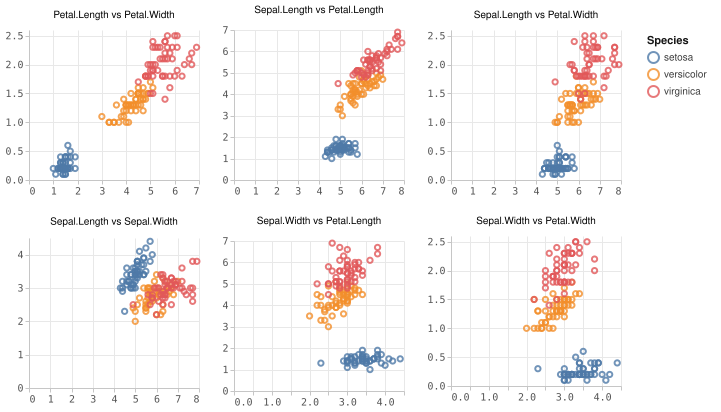

In [2]:
rows = []
for i in range(4):
    for j in range(i + 1, 4):
        xi = np.asarray(data[measurements[i]], dtype=float)
        xj = np.asarray(data[measurements[j]], dtype=float)
        for k in range(data.height):
            rows.append({
                "x": float(xi[k]),
                "y": float(xj[k]),
                "species": species[k],
                "pair": f"{measurements[i]} vs {measurements[j]}",
            })
pairs = pl.DataFrame(rows)

alt.Chart(pairs).mark_point(size=28, opacity=0.8).encode(
    x=alt.X("x:Q", title=None),
    y=alt.Y("y:Q", title=None),
    color=alt.Color("species:N", title="Species"),
    tooltip=["x:Q", "y:Q", "species:N"],
).properties(
    width=170, height=150,
).facet(
    facet=alt.Facet("pair:N", title=None), columns=3,
).resolve_scale(x="independent", y="independent")

## Multinomial model

A multinomial model assigns one of $K$ unordered classes to each plant. It
fits one function per class, expressed as a log-odds against a reference
class: the logarithm of the ratio P(class)/P(reference). The three class
probabilities are recovered from the log-odds by the softmax, which divides
each exp(log-odds) by the sum over the classes, so the probabilities sum
to 1.

The model below uses one smooth base learner per measurement and the
multinomial family, which shares the four learners across the three log-odds:
one fit produces all three functions. As in the earlier studies, boosting
adds small updates to the log-odds, each scaled by the shrinkage factor
$\nu = 0.1$, and mstop counts the updates.

Choosing mstop needs a held-out sample. The cross-validation routine used in
the other studies is not wired up for the multinomial expansion in mboostrs,
so this study does the same check by hand: one fifth of the plants is set
aside as validation, the model is fitted on the remaining four fifths for a
grid of mstop values, and the held-out deviance — the negative log likelihood
of the validation plants — is read off.

The validation deviance keeps falling to the end of the grid even after
label accuracy changes little. More updates increase the probabilities
assigned to correctly classified plants. We use the 200-iteration fit for
classification and examine how a longer fit changes probability calibration
in the final section.

In [3]:
folds = mb.cv_weights(data.height, type="kfold", B=5, seed=11)
# Reuse the declared folds so comparisons differ by model, not by split.
validation = folds[:, 4] == 0

train = folds[:, 4] > 0

formula = (
    "Species ~ bbs(Petal.Length, df=3) + bbs(Petal.Width, df=3)"
    " + bbs(Sepal.Length, df=3) + bbs(Sepal.Width, df=3)"
)

family = mb.Multinomial()

arrays = {c: np.asarray(data[c]) for c in [*measurements, "Species"]}

grid = np.concatenate([np.arange(10, 101, 10), np.arange(150, 1001, 50)])

deviance = []

for m in grid:
    fit = mb.gamboost(
        formula, data={c: arr[train] for c, arr in arrays.items()},
        family=family, control=mb.boost_control(m, 0.1),
    )
    p_val = fit.predict(
        newdata={c: arr[validation] for c, arr in arrays.items()},
        type="response",
    )
    truth_idx = np.array([list(names).index(s) for s in species[validation]])
    deviance.append(-np.log(p_val[np.arange(len(p_val)), truth_idx]).sum())

mstop = 200


deviance at 10 iterations: 29.67; at 1000 iterations: 7.35 (still falling)


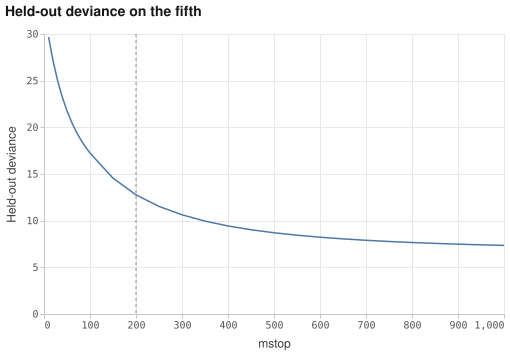

In [4]:
dev = pl.DataFrame({"mstop": grid, "deviance": deviance})

print(f"deviance at 10 iterations: {deviance[0]:.2f}; "
      f"at 1000 iterations: {deviance[-1]:.2f} (still falling)")

line = alt.Chart(dev).mark_line(strokeWidth=1.5).encode(
    x=alt.X("mstop:Q", title="mstop"),
    y=alt.Y("deviance:Q", title="Held-out deviance"),
)

rule = alt.Chart(pl.DataFrame({"m": [mstop]})).mark_rule(
    color="#8d8d8d", strokeDash=[3, 3], strokeWidth=1,
).encode(x="m:Q")

alt.layer(line, rule).properties(
    width=460, height=280, title="Held-out deviance on the fifth",
).interactive()


## Fitted class probabilities

The model is refitted on all 150 plants at the chosen mstop, and the class
probabilities are read off. The chart below plots the probability of each
species against petal length — the measurement that separates best. Setosa
probability is high for short petals and low for long ones,
while versicolor and virginica trade the middle ground.

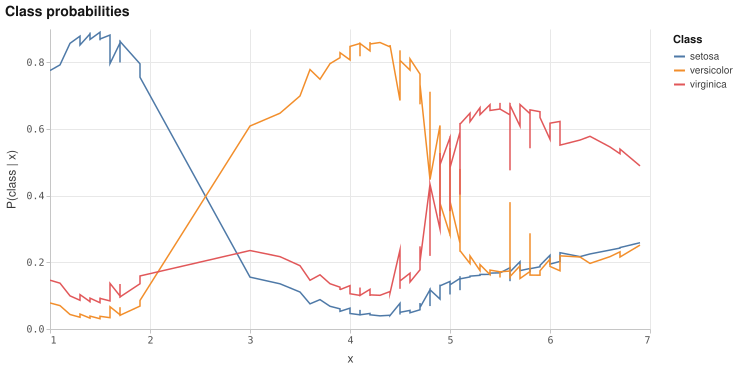

In [5]:
model = mb.gamboost(
    formula, data=data, family=family,
    control=mb.boost_control(mstop, 0.1),
)
prob = model.predict(type="response")
plot_multinomial(model)

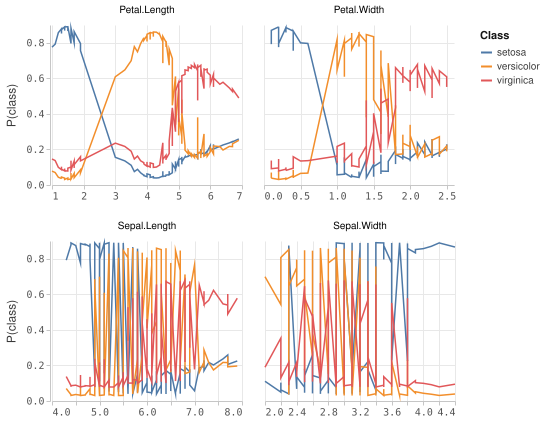

In [6]:
rows = []
for cname in measurements:
    x = np.asarray(data[cname], dtype=float)
    for i in range(data.height):
        for k, name in enumerate(names):
            rows.append({
                "x": float(x[i]),
                "probability": float(prob[i, k]),
                "class": name,
                "measurement": cname,
            })
prob_frame = pl.DataFrame(rows).sort(["measurement", "class", "x"])

alt.Chart(prob_frame).mark_line(strokeWidth=1.5).encode(
    x=alt.X("x:Q", title=None),
    y=alt.Y("probability:Q", title="P(class)"),
    color=alt.Color("class:N", title="Class"),
).properties(width=190, height=160).facet(
    facet=alt.Facet("measurement:N", title=None), columns=2,
).resolve_scale(x="independent")

## Classification accuracy

The model's label is the species with the highest probability. The table
counts, for each species assigned by the collector, how often the model
labels those plants as each of the three species.

In [7]:
label = names[np.argmax(prob, axis=1)]
rows = []
for actual in names:
    row = {"assigned by the collector": actual}
    for predicted in names:
        row[predicted] = int(np.sum((species == actual) & (label == predicted)))
    rows.append(row)
display(pl.DataFrame(rows))
print(f"the model labels {100 * (label == species).mean():.1f}% of plants correctly")

assigned by the collector,setosa,versicolor,virginica
str,i64,i64,i64
"""setosa""",50,0,0
"""versicolor""",0,48,2
"""virginica""",0,5,45


the model labels 95.3% of plants correctly


## Reliability diagram

A probability is calibrated when events assigned predicted
probability $p$ occur with frequency $p$. The reliability diagram reads this
directly: the predictions are ordered and cut into equal-sized bins, and each
bin contributes one point — the average predicted probability against the
observed rate of the event in that bin. Points on the 45-degree line are
calibrated. Points above the line mean the event happens more often than the
prediction says — the model is under-confident; points below it mean
over-confidence.

The reference panel below shows the two shapes before the real check. Both
predictors were simulated, so the true probabilities are known: one uses them
directly, the other halves every log-odds, which pulls every probability
toward 0.5. The halved predictor's curve
has true probabilities below its predictions below 0.5 and above them above
0.5: a prediction of 0.4 corresponds to a true probability below 0.4, and a
prediction of 0.6 to one above 0.6. Halving the log-odds pulls probabilities
toward 0.5. The simulated observed rates fluctuate around that relationship.

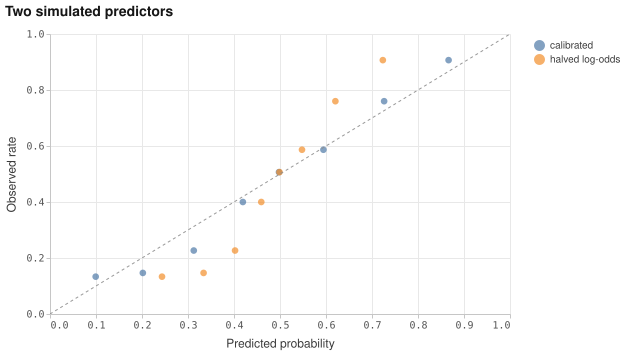

In [8]:
rng = np.random.default_rng(7)
n_ref = 600
x_ref = rng.normal(size=n_ref)
true_logit = 1.4 * x_ref
true_p = 1.0 / (1.0 + np.exp(-true_logit))
y_ref = rng.binomial(1, true_p)
shrunk_p = 1.0 / (1.0 + np.exp(-true_logit / 2))
# Fix the random draw so the resampling result is reproducible.
def binned(predicted, observed):
    order = np.argsort(predicted)
    p = predicted[order]
    o = observed[order]
    edges = np.linspace(0, len(p), 9).astype(int)
    out = []
    for i in range(8):
        lo, hi = edges[i], edges[i + 1]
        out.append({"predicted": float(p[lo:hi].mean()), "observed": float(o[lo:hi].mean())})
    return out

rows = [dict(v, predictor="calibrated") for v in binned(true_p, y_ref)]
rows += [dict(v, predictor="halved log-odds") for v in binned(shrunk_p, y_ref)]
ref_frame = pl.DataFrame(rows)

pts = alt.Chart(ref_frame).mark_circle(size=45).encode(
    x=alt.X("predicted:Q", title="Predicted probability", scale=alt.Scale(domain=[0, 1])),
    y=alt.Y("observed:Q", title="Observed rate", scale=alt.Scale(domain=[0, 1])),
    color=alt.Color("predictor:N", title=None),
)
diag = alt.Chart(pl.DataFrame({"x": [0, 1], "y": [0, 1]})).mark_line(
    color="#8d8d8d", strokeWidth=1, strokeDash=[3, 3], opacity=0.9,
).encode(x="x:Q", y="y:Q")
alt.layer(pts, diag).properties(
    width=460, height=280, title="Two simulated predictors",
).interactive()


## Out-of-fold reliability

The check must use predictions the model did not train on: a model's
in-sample probabilities reflect the fit, and an overfitted model looks well
calibrated on its own data. The study produces out-of-fold predictions by
stacking: the plants are split into five folds, the model is fitted five
times, each time leaving one fifth out, and the predictions for each held-out
fifth are collected into one prediction per plant. The chosen mstop is used
in every fold. The same stacked predictions also give an out-of-fold label
accuracy, printed below the chart.

The diagram reads the reliability of the label. For each plant, take the
probability the model assigns to its predicted species — the largest of the
three — and the event "the label is correct". If the probabilities were
calibrated, a plant scored at 0.8 would be labelled correctly 80% of the
time.

out-of-fold label accuracy: 95.3%


/tmp/ipykernel_67107/2024137395.py:8: ExtrapolationWarning: 2 learner(s) are asked to predict outside the range they were fitted on. bbs(Sepal.Width), covariate Sepal.Width: 1 above 4.2 (worst 0.091 training ranges out); bbs(Sepal.Length), covariate Sepal.Length: 1 above 7.7 (worst 0.059 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.091 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  oof[~in_fold] = fit.predict(
/tmp/ipykernel_67107/2024137395.py:8: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(Sepal.Width), covariate Sepal.Width: 1 below 2.2 (worst 0.091 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does 

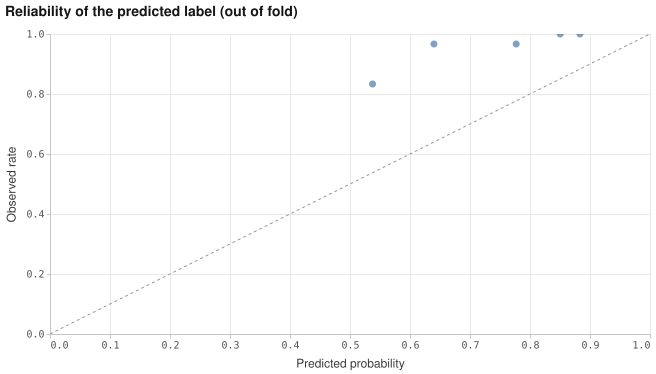

In [9]:
oof = np.zeros((data.height, len(names)))
for f in range(folds.shape[1]):
    in_fold = folds[:, f] > 0
    fit = mb.gamboost(
        formula, data={c: arr[in_fold] for c, arr in arrays.items()},
        family=family, control=mb.boost_control(mstop, 0.1),
    )
    oof[~in_fold] = fit.predict(
        newdata={c: arr[~in_fold] for c, arr in arrays.items()},
        type="response",
    )

max_prob = oof.max(axis=1)
correct = (names[np.argmax(oof, axis=1)] == species).astype(float)
print(f"out-of-fold label accuracy: {100 * correct.mean():.1f}%")

plot_reliability(max_prob, correct, n_bins=5,
                 title="Reliability of the predicted label (out of fold)")

In [10]:
order = np.argsort(max_prob)
edges = np.linspace(0, data.height, 6).astype(int)
for i in range(5):
    lo, hi = edges[i], edges[i + 1]
    print(f"predicted {max_prob[order[lo:hi]].mean():.3f} "
          f"-> observed {correct[order[lo:hi]].mean():.3f} "
          f"(n = {hi - lo})")
setosa_p = oof[species == "setosa", list(names).index("setosa")]
print(f"setosa plants: mean predicted P(setosa) = {setosa_p.mean():.3f}, "
      f"observed rate = 1.000")

predicted 0.538 -> observed 0.833 (n = 30)
predicted 0.640 -> observed 0.967 (n = 30)
predicted 0.777 -> observed 0.967 (n = 30)
predicted 0.850 -> observed 1.000 (n = 30)
predicted 0.883 -> observed 1.000 (n = 30)
setosa plants: mean predicted P(setosa) = 0.862, observed rate = 1.000


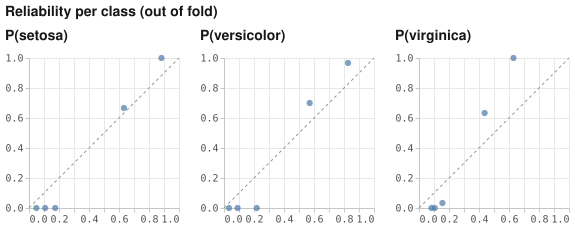

In [11]:
def per_class_bins(predicted, observed):
    order = np.argsort(predicted)
    p = predicted[order]
    o = observed[order]
    edges = np.linspace(0, len(p), 6).astype(int)
    out = []
    for i in range(5):
        lo, hi = edges[i], edges[i + 1]
        out.append({"predicted": float(p[lo:hi].mean()), "observed": float(o[lo:hi].mean())})
    return out

panels = []
for k, name in enumerate(names):
    panel = pl.DataFrame(per_class_bins(oof[:, k], (species == name).astype(float)))
    pts = alt.Chart(panel).mark_circle(size=40).encode(
        x=alt.X("predicted:Q", title=None, scale=alt.Scale(domain=[0, 1])),
        y=alt.Y("observed:Q", title=None, scale=alt.Scale(domain=[0, 1])),
    )
    diag = alt.Chart(pl.DataFrame({"x": [0, 1], "y": [0, 1]})).mark_line(
        color="#8d8d8d", strokeWidth=1, strokeDash=[3, 3], opacity=0.9,
    ).encode(x="x:Q", y="y:Q")
    panels.append(alt.layer(pts, diag).properties(
        width=150, height=150, title=f"P({name})",
    ))
alt.hconcat(*panels).properties(title="Reliability per class (out of fold)")

## Extension: early stopping and confidence

Every boosting iteration adds $\nu$ times a base-learner fit to the
log-odds. Stopping after fewer updates limits how far the fitted probabilities
can move from their initial values. The comparison below holds $\nu$ and the
folds fixed and changes the iteration count, so it measures the effect of
continuing this fitting path.

The chart below compares out-of-fold reliability for the working fit and
a fit five times longer. More iterations move the curve toward the
diagonal — the top bin rises from 0.88 to 0.98 — while the label accuracy
barely moves. On this fitting path, additional iterations change confidence
more than label accuracy. Even at 1000 iterations the curve is not on the
diagonal; this comparison does not establish calibrated probabilities for
the overlapping species.

In [12]:
oof_long = np.zeros((data.height, len(names)))
# Reuse the declared folds so comparisons differ by model, not by split.
for f in range(folds.shape[1]):
    in_fold = folds[:, f] > 0
    fit = mb.gamboost(
        formula, data={c: arr[in_fold] for c, arr in arrays.items()},
        family=family, control=mb.boost_control(1000, 0.1),
    )
    oof_long[~in_fold] = fit.predict(
        newdata={c: arr[~in_fold] for c, arr in arrays.items()},
        type="response",
    )

max_long = oof_long.max(axis=1)

correct_long = (names[np.argmax(oof_long, axis=1)] == species).astype(float)

print(f"out-of-fold label accuracy at 1000 iterations: "
      f"{100 * correct_long.mean():.1f}%")

setosa_long = oof_long[species == "setosa", list(names).index("setosa")]

setosa_p = oof[species == "setosa", list(names).index("setosa")]

print(f"setosa plants: mean predicted P(setosa) {setosa_p.mean():.3f} at "
      f"200 iterations, {setosa_long.mean():.3f} at 1000 iterations "
      "(observed rate 1.000)")


/tmp/ipykernel_67107/614786646.py:9: ExtrapolationWarning: 2 learner(s) are asked to predict outside the range they were fitted on. bbs(Sepal.Width), covariate Sepal.Width: 1 above 4.2 (worst 0.091 training ranges out); bbs(Sepal.Length), covariate Sepal.Length: 1 above 7.7 (worst 0.059 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.091 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  oof_long[~in_fold] = fit.predict(
/tmp/ipykernel_67107/614786646.py:9: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(Sepal.Width), covariate Sepal.Width: 1 below 2.2 (worst 0.091 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit do

out-of-fold label accuracy at 1000 iterations: 96.0%
setosa plants: mean predicted P(setosa) 0.862 at 200 iterations, 0.970 at 1000 iterations (observed rate 1.000)


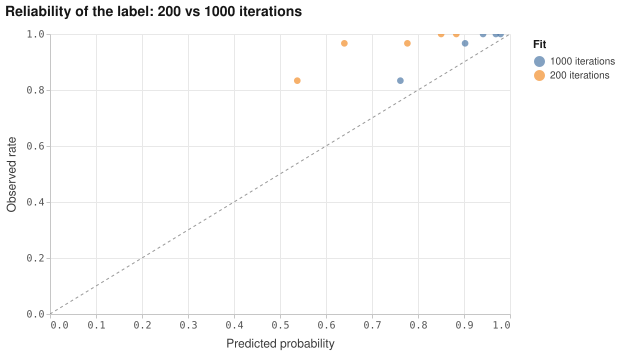

In [13]:
def reliability_bins(predicted, observed):
    order = np.argsort(predicted)
    p = predicted[order]
    o = observed[order]
    edges = np.linspace(0, len(p), 6).astype(int)
    return [{"predicted": float(p[lo:hi].mean()), "observed": float(o[lo:hi].mean())}
            for lo, hi in zip(edges[:-1], edges[1:])]
# Plot the quantities interpreted in the following paragraph.
rows = [dict(v, fit="200 iterations") for v in reliability_bins(max_prob, correct)]

rows += [dict(v, fit="1000 iterations") for v in reliability_bins(max_long, correct_long)]

comp = pl.DataFrame(rows)

pts = alt.Chart(comp).mark_circle(size=45).encode(
    x=alt.X("predicted:Q", title="Predicted probability", scale=alt.Scale(domain=[0, 1])),
    y=alt.Y("observed:Q", title="Observed rate", scale=alt.Scale(domain=[0, 1])),
    color=alt.Color("fit:N", title="Fit"),
)

diag = alt.Chart(pl.DataFrame({"x": [0, 1], "y": [0, 1]})).mark_line(
    color="#8d8d8d", strokeWidth=1, strokeDash=[3, 3], opacity=0.9,
).encode(x="x:Q", y="y:Q")

alt.layer(pts, diag).properties(
    width=460, height=280, title="Reliability of the label: 200 vs 1000 iterations",
).interactive()


## Conclusions

### Supported claims

- The four measurements separate the species, and the model's label is
  correct for 95.3% of plants out of fold —
  every setosa, 48 of 50 versicolor, 45 of 50 virginica.
- The probabilities are under-confident, not over-confident: the reliability
  curve sits above the diagonal at every bin — plants scored at 0.64 are
  labelled correctly 97% of the time, and setosa plants are scored at 0.86
  on average while always being setosa.
- Continuing the same fitting path to 1000 iterations moves the curve
  toward the diagonal (the top bin rises from 0.88 to 0.98) while label
  accuracy changes from 95.3% to 96.0%. This comparison measures the effect
  of iteration count at the fixed shrinkage factor.
- If the deliverable is the label, the working fit is enough: the
  under-confident probabilities do not change the ranking of the species.

### Unsupported claims

- That a predicted probability of 0.64 means a 64% chance: plants scored at
  that level are labelled correctly 97% of the time.
- That this fit is overconfident: the reported reliability bins instead show
  observed correctness above the predicted probability.

### Out of scope

- Species beyond the three measured, other growing conditions, and the cost
  of a wrong assignment: the data are 150 plants from one survey, and the
  study never priced a misclassification.
- Calibrated probabilities for the overlapping pair in the middle region:
  the reliability comparison does not establish calibration in that region,
  even at 1000 iterations.